# Formative 2: Hidden Markov Model for Human Activity Recognition
Individual project. Gaussian-emission HMM implemented from scratch with numpy. Run all cells top to bottom.

**Background and motivation (edit: one paragraph, my own use case).** _Write which real application I am targeting, e.g. fall detection or fitness tracking, and why recognising activity states from noisy phone sensors is needed._

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, copy
from pathlib import Path
from scipy.signal import butter, filtfilt
from IPython.display import display
np.random.seed(0)

FS = 50              # target sampling rate (Hz)
WIN, STEP = 100, 50  # 2 s window, 50% overlap at 50 Hz
TRIM_S = 0.5         # seconds trimmed from each end of every training file
ACTS = ['still', 'standing', 'walking', 'jumping']
A2I = {a: i for i, a in enumerate(ACTS)}
DATA, FIG = Path('data'), Path('figures'); FIG.mkdir(exist_ok=True)
FLOOR = 1e-3         # variance floor (z-scored units)

## 1. Data collection and pre-processing
Recordings: Sensor Logger, accelerometer + gyroscope (the accelerometer channel is the app’s TotalAcceleration, which includes gravity; its plain "Accelerometer" file is gravity-removed), nominal rate **(edit: 50 Hz, or 50 Hz and 100 Hz for different sessions)**. Continuous takes per activity were cut into 10 s files (`src/prepare_data.py`); the first 3 s and last 2 s of every take were dropped. **Edit: state phone model, sessions, locations, and the activity protocol for each.**

Phones never deliver a perfectly uniform rate, so every file is (1) audited for measured rate and jitter, (2) low-pass filtered if its native rate is above 50 Hz (anti-aliasing), (3) linearly interpolated onto a uniform 50 Hz grid, (4) trimmed by 0.5 s at each end.

In [2]:
def load_merged(path):
    df = pd.read_csv(path)
    return df[['t','ax','ay','az','gx','gy','gz']].dropna().sort_values('t').reset_index(drop=True)

def measured_fs(t):
    d = np.diff(t); return 1/np.median(d), np.std(d)*1000     # Hz, jitter (ms)

def resample(df, fs=FS):
    """Uniform grid from t=0; anti-alias low-pass first when the native rate exceeds fs."""
    t = df['t'].to_numpy() - df['t'].iloc[0]
    native = 1/np.median(np.diff(t))
    X = df[['ax','ay','az','gx','gy','gz']].to_numpy()
    if native > fs*1.05:
        b, a = butter(4, 0.4*fs/(native/2)); X = filtfilt(b, a, X, axis=0)
    tg = np.arange(0, t[-1], 1/fs)
    return np.column_stack([np.interp(tg, t, X[:, j]) for j in range(6)])

def trim(arr, sec=TRIM_S, fs=FS):
    n = int(sec*fs); return arr[n:-n] if len(arr) > 2*n else arr

In [3]:
rows, train_files = [], []
for f in sorted((DATA/'train').glob('*.csv')):
    act = f.stem.split('_')[0]
    if act not in A2I: continue
    df = load_merged(f); hz, jit = measured_fs(df['t'].to_numpy())
    x = trim(resample(df))
    rows.append(dict(file=f.name, activity=act, raw_seconds=df['t'].iloc[-1]-df['t'].iloc[0], measured_hz=hz, jitter_ms=jit, sec_after_trim=len(x)/FS))
    train_files.append((act, x))
audit = pd.DataFrame(rows)
print('Training files:', len(audit), '| raw file length range (s):', audit.raw_seconds.min().round(1), '-', audit.raw_seconds.max().round(1))
display(audit.groupby('activity').agg(files=('file','count'), seconds_after_trim=('sec_after_trim','sum'),
        mean_hz=('measured_hz','mean'), mean_jitter_ms=('jitter_ms','mean')).round(2))
assert len(audit) >= 50, 'rubric target: >= 50 files'
assert (audit.groupby('activity').sec_after_trim.sum() >= 90).all(), 'rubric target: >= 90 s per activity'

Training files: 88 | raw file length range (s): 10.0 - 10.0


,files,seconds_after_trim,mean_hz,mean_jitter_ms
activity,,,,
jumping,24,215.76,66.65,0.05
standing,24,215.72,66.65,0.05
still,16,143.84,74.97,0.06
walking,24,215.70,66.65,0.13


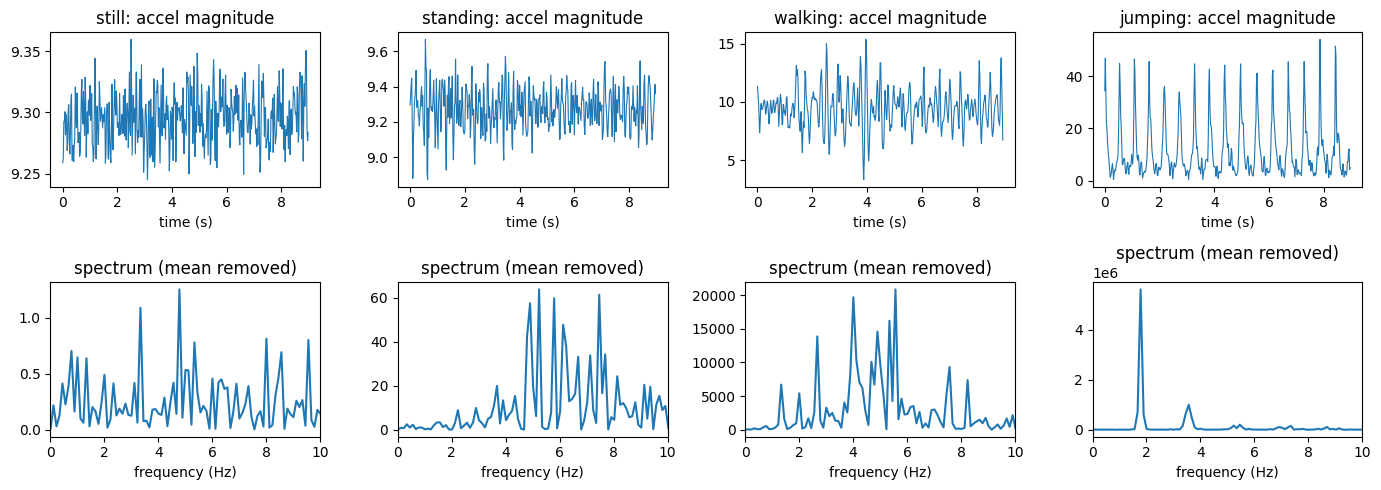

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(14, 5))
for j, act in enumerate(ACTS):
    x = next(x for a, x in train_files if a == act)
    am = np.linalg.norm(x[:, :3], axis=1); t = np.arange(len(am))/FS
    ax[0, j].plot(t, am, lw=.8); ax[0, j].set_title(f'{act}: accel magnitude'); ax[0, j].set_xlabel('time (s)')
    P = np.abs(np.fft.rfft(am-am.mean()))**2; ax[1, j].plot(np.fft.rfftfreq(len(am), 1/FS), P)
    ax[1, j].set_xlim(0, 10); ax[1, j].set_title('spectrum (mean removed)'); ax[1, j].set_xlabel('frequency (Hz)')
plt.tight_layout(); plt.savefig(FIG/'sample_signals.png', dpi=150); plt.show()

## 2. Feature extraction
**Window logic.** 2 s = 100 samples at 50 Hz. Walking and jumping cadences are roughly 1.5-3 Hz, so a window holds 3-6 cycles; the FFT resolution is 1/2 s = 0.5 Hz; Nyquist is 25 Hz, far above body-motion content. 50% overlap (step = 50 samples) doubles the number of observations without new data.

| Feature | Domain | Why it helps |
|---|---|---|
| `a_mean` | time | mean accelerometer magnitude: gravity offset plus motion bias |
| `a_mx, a_my, a_mz` | time | per-axis means encode gravity direction, i.e. phone orientation: flat on a table (still) vs held at the waist (standing) |
| `a_std` | time | motion variability: lowest for still, small for standing, high for walking, highest for jumping |
| `a_rms` | time | signal energy including the DC component |
| `a_sma` | time | signal magnitude area: overall activity level across the three axes |
| `corr_xy, corr_xz, corr_yz` | time | axis coupling: vertical jumps vs forward-backward sway in walking |
| `g_std` | time | rotational variability (gyroscope magnitude): arm and hip swing in walking vs vertical jumping |
| `a_domf` | frequency (FFT) | dominant frequency of the mean-removed signal: gait vs jump cadence |
| `a_energy` | frequency (FFT) | spectral energy: total oscillatory power |
| `a_sent` | frequency (FFT) | spectral entropy: periodic motion (low) vs noise-like (high) |
| `g_domf` | frequency (FFT) | gyroscope cadence: confirms periodicity from a second sensor |

**Normalization.** Z-score per feature using the **training** mean and standard deviation only, reused unchanged on test windows (fitting on test data would leak information). Justification: features have different units and ranges, and Gaussian emissions with diagonal covariance are scale-sensitive; z-scoring puts all features on a comparable scale and makes the variance floor meaningful.

In [5]:
FEATS = ['a_mean','a_mx','a_my','a_mz','a_std','a_rms','a_sma','corr_xy','corr_xz','corr_yz','g_std','a_domf','a_energy','a_sent','g_domf']
FREQ  = ['a_domf','a_energy','a_sent','g_domf']

def spectrum(sig):
    P = np.abs(np.fft.rfft(sig - sig.mean()))**2
    return np.fft.rfftfreq(len(sig), 1/FS), P

def features(w):
    a, g = w[:, :3], w[:, 3:]
    am, gm = np.linalg.norm(a, axis=1), np.linalg.norm(g, axis=1)
    with np.errstate(all='ignore'):
        c = np.nan_to_num(np.corrcoef(a.T))
    fa, Pa = spectrum(am); fg, Pg = spectrum(gm); pn = Pa[1:]/(Pa[1:].sum()+1e-12)
    return [am.mean(), a[:,0].mean(), a[:,1].mean(), a[:,2].mean(), am.std(), np.sqrt((am**2).mean()), np.abs(a).sum(1).mean(),
            c[0,1], c[0,2], c[1,2], gm.std(),
            fa[1:][Pa[1:].argmax()], Pa.sum()/len(am), -(pn*np.log(pn+1e-12)).sum(), fg[1:][Pg[1:].argmax()]]

def windows(x, win=WIN, step=STEP):
    return np.array([features(x[i:i+win]) for i in range(0, len(x)-win+1, step)])

train_win = [(act, windows(x)) for act, x in train_files]
allX = np.vstack([w for _, w in train_win])
MU, SD = allX.mean(0), allX.std(0) + 1e-9        # training statistics only
zs = lambda X: (X - MU)/SD
print('training windows:', len(allX), '| features:', len(FEATS))

training windows: 661 | features: 15


## 3. HMM setup and implementation
| Element | Definition here |
|---|---|
| Hidden states Z | still, standing, walking, jumping |
| Observations X | 15-dimensional z-scored feature vector per 2 s window |
| Transition matrix A | P(next window's activity \| current activity), 4x4 |
| Emission B | diagonal Gaussian per state, P(x \| state) |
| Initial probabilities pi | P(first window's activity) |

**Algorithms and how they tie to the metrics.** Viterbi returns the single most probable state path; each decoded window is compared with its true label to give the confusion matrix, sensitivity, specificity and accuracy. Baum-Welch (EM) re-estimates A, pi and the Gaussian parameters by maximising the likelihood; the forward algorithm supplies the log-likelihood used as the convergence criterion. Posterior decoding from forward-backward alone would pick each window's state independently and could output paths the transition matrix forbids, so Viterbi is used for evaluation. All recursions run in log-space to avoid underflow with 15 features.

**Initialisation.** Parameters are initialised from the labelled training windows (supervised), which also fixes the label-permutation problem of unsupervised EM, where "state 2" could end up meaning any activity. Accuracy is reported before and after Baum-Welch.

In [6]:
def lse(a, axis):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

class GaussianHMM:
    """HMM with diagonal-Gaussian emissions; hidden states are the activities."""
    def __init__(self, K, floor=FLOOR): self.K, self.floor = K, floor

    def init_from_labels(self, Xs, Ys, smooth=1e-3):
        X, y = np.vstack(Xs), np.concatenate(Ys); K = self.K
        self.mu = np.array([X[y==k].mean(0) for k in range(K)])
        self.var = np.array([X[y==k].var(0) for k in range(K)]) + self.floor
        A, pi = np.full((K, K), smooth), np.full(K, smooth)       # smoothing keeps log(A) finite
        for yy in Ys:
            pi[yy[0]] += 1
            for a, b in zip(yy[:-1], yy[1:]): A[a, b] += 1
        self.A, self.pi = A/A.sum(1, keepdims=True), pi/pi.sum()
        return self

    def log_emission(self, X):                                    # (T, K)
        return -0.5*(np.log(2*np.pi*self.var)[None] + (X[:, None, :]-self.mu[None])**2/self.var[None]).sum(-1)

    def forward(self, logB):
        T, K = logB.shape; la = np.zeros((T, K)); lA = np.log(self.A)
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, T): la[t] = logB[t] + lse(la[t-1][:, None] + lA, 0)
        return la, lse(la[-1], 0)                                 # log-alpha, log-likelihood

    def backward(self, logB):
        T, K = logB.shape; lb = np.zeros((T, K)); lA = np.log(self.A)
        for t in range(T-2, -1, -1): lb[t] = lse(lA + (logB[t+1] + lb[t+1])[None, :], 1)
        return lb

    def viterbi(self, X):
        logB = self.log_emission(X); T, K = logB.shape; lA = np.log(self.A)
        d = np.zeros((T, K)); psi = np.zeros((T, K), int); d[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            s = d[t-1][:, None] + lA; psi[t] = s.argmax(0); d[t] = s.max(0) + logB[t]
        path = np.zeros(T, int); path[-1] = d[-1].argmax()
        for t in range(T-2, -1, -1): path[t] = psi[t+1, path[t+1]]
        return path

    def fit(self, Xs, tol=1e-6, max_iter=200):
        """Baum-Welch over several sequences. Stops when |dLL|/|LL| < tol (max_iter is only a backstop).
        Returns the total log-likelihood after each E-step."""
        K, D = self.K, Xs[0].shape[1]; hist = []
        for it in range(max_iter):
            A_num = np.zeros((K, K)); pi_acc = np.zeros(K)
            g_sum = np.zeros(K); gx = np.zeros((K, D)); gx2 = np.zeros((K, D)); ll_tot = 0.0; lA = np.log(self.A)
            for X in Xs:                                          # E-step
                logB = self.log_emission(X); la, ll = self.forward(logB); lb = self.backward(logB)
                gam = np.exp(la + lb - ll)
                xi = np.exp(la[:-1, :, None] + lA[None] + (logB[1:] + lb[1:])[:, None, :] - ll)
                A_num += xi.sum(0); pi_acc += gam[0]
                g_sum += gam.sum(0); gx += gam.T @ X; gx2 += gam.T @ (X**2); ll_tot += ll
            hist.append(ll_tot)
            if it > 0 and abs(hist[-1]-hist[-2]) < tol*abs(hist[-2]): break   # convergence check
            A = A_num + 1e-6; self.A = A/A.sum(1, keepdims=True)  # M-step
            self.pi = (pi_acc + 1e-6)/(pi_acc.sum() + K*1e-6)
            self.mu = gx/g_sum[:, None]
            self.var = np.maximum(gx2/g_sum[:, None] - self.mu**2, 0) + self.floor
        self.n_iter = len(hist)
        return hist

### Training sequences
Training windows are chained in plausible orders (e.g. still -> standing -> walking -> jumping -> standing), each file used once. The learned A therefore reflects **this construction of sequences, not behaviour discovered from the data**; the report says so.

24 training sequences, 661 windows
Baum-Welch evaluations: 14 | final log-likelihood: -731.75


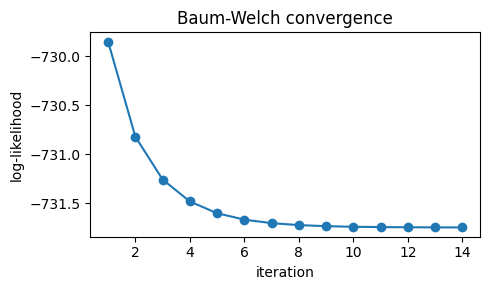

In [7]:
ORDERS = [['still','standing','walking','jumping','standing'],
          ['walking','jumping','standing','still'],
          ['standing','walking','standing','jumping','still'],
          ['jumping','walking','still','standing']]
pool = {a: [w for act, w in train_win if act == a] for a in ACTS}
rng = np.random.default_rng(0)
for a in ACTS: rng.shuffle(pool[a])
Xs, Ys, k = [], [], 0
while any(pool.values()):
    order = ORDERS[k % len(ORDERS)]; k += 1; xs, ys = [], []
    for a in order:
        if pool[a]:
            w = pool[a].pop(); xs.append(zs(w)); ys.append(np.full(len(w), A2I[a]))
    if xs: Xs.append(np.vstack(xs)); Ys.append(np.concatenate(ys))
print(len(Xs), 'training sequences,', sum(len(x) for x in Xs), 'windows')

hmm0 = GaussianHMM(4).init_from_labels(Xs, Ys)       # before Baum-Welch
hmm = copy.deepcopy(hmm0)
hist = hmm.fit(Xs, tol=1e-6, max_iter=200)           # after Baum-Welch
print('Baum-Welch evaluations:', hmm.n_iter, '| final log-likelihood:', round(hist[-1], 2))
plt.figure(figsize=(5, 3)); plt.plot(range(1, len(hist)+1), hist, marker='o'); plt.xlabel('iteration'); plt.ylabel('log-likelihood')
plt.title('Baum-Welch convergence'); plt.tight_layout(); plt.savefig(FIG/'loglik.png', dpi=150); plt.show()

## 4. Evaluation on unseen data
**Edit: describe how the two test recordings were obtained** (new session / different day / different place / phone / person), and state plainly if the test is single-subject. Test files were never used for training or for the scaler. Ground-truth segments come from `data/test/test_labels.csv`; windows that fall in unlabelled gaps (e.g. picking the phone up) are decoded but excluded from the metrics.

Sampling-rate table (measured rate and jitter per take / test file; target grid 50 Hz):


,source,measured_hz,jitter_ms
0,jumping_s1,50.0,0.04
1,jumping_s2,50.0,0.01
2,jumping_s3,50.0,0.02
3,jumping_s4,50.0,0.03
4,jumping_s5,99.9,0.17
5,jumping_s6,99.9,0.01
6,standing_s1,50.0,0.11
7,standing_s2,50.0,0.01
8,standing_s3,99.9,0.02
9,still_s1,99.9,0.11


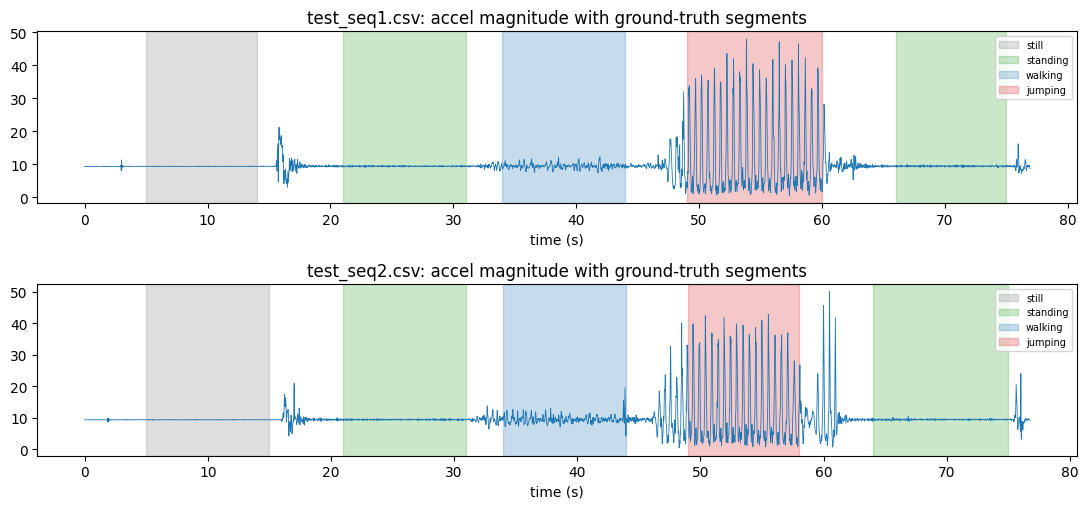

In [8]:
labels = pd.read_csv(DATA/'test'/'test_labels.csv')
test_seq, rate_rows = [], []
for f in sorted((DATA/'test').glob('test_seq*.csv')):
    df = load_merged(f); hz, jit = measured_fs(df['t'].to_numpy()); rate_rows.append(dict(source=f.name, measured_hz=round(hz,1), jitter_ms=round(jit,2)))
    x = resample(df)                                       # not trimmed: labels are seconds from file start
    W = windows(x); centers = (np.arange(len(W))*STEP + WIN/2)/FS; y = np.full(len(W), -1)
    for _, r in labels[labels.file == f.name].iterrows():
        y[(centers >= r.start_s) & (centers < r.end_s)] = A2I[r.activity]
    test_seq.append((f.name, zs(W), y, x))
train_rates = [dict(source=tk, measured_hz=round(g.measured_hz.mean(),1), jitter_ms=round(g.jitter_ms.mean(),2))
               for tk, g in audit.assign(take=audit.file.str.rsplit('_', n=1).str[0]).groupby('take')]
rate_rows = train_rates + rate_rows
print('Sampling-rate table (measured rate and jitter per take / test file; target grid 50 Hz):'); display(pd.DataFrame(rate_rows))
assert len(test_seq) >= 2, 'rubric: 2 test files'

# Check that the label segments line up with the signal (fix test_labels.csv if they do not)
cols = dict(zip(ACTS, ['tab:gray','tab:green','tab:blue','tab:red']))
fig, axs = plt.subplots(len(test_seq), 1, figsize=(11, 2.6*len(test_seq)), squeeze=False)
for i, (name, _, _, x) in enumerate(test_seq):
    am = np.linalg.norm(x[:, :3], axis=1); axs[i, 0].plot(np.arange(len(am))/FS, am, lw=.6); seen = set()
    for _, r in labels[labels.file == name].iterrows():
        axs[i, 0].axvspan(r.start_s, r.end_s, color=cols[r.activity], alpha=.25, label=None if r.activity in seen else r.activity); seen.add(r.activity)
    axs[i, 0].set_title(name + ': accel magnitude with ground-truth segments'); axs[i, 0].set_xlabel('time (s)'); axs[i, 0].legend(loc='upper right', fontsize=7)
plt.tight_layout(); plt.savefig(FIG/'test_label_check.png', dpi=150); plt.show()

In [9]:
def confusion(y, p, K=4):
    C = np.zeros((K, K), int)
    for a, b in zip(y, p): C[a, b] += 1
    return C

def metrics_table(C):
    N = C.sum(); rows = []
    for k, a in enumerate(ACTS):
        TP = C[k, k]; FN = C[k].sum()-TP; FP = C[:, k].sum()-TP; TN = N-TP-FN-FP
        rows.append({'State (Activity)': a, 'Number of Samples': int(C[k].sum()),
                     'Sensitivity': TP/(TP+FN) if TP+FN else np.nan, 'Specificity': TN/(TN+FP) if TN+FP else np.nan,
                     'Overall Accuracy': (TP+TN)/N})
    rows.append({'State (Activity)': 'ALL', 'Number of Samples': int(N), 'Sensitivity': np.nan, 'Specificity': np.nan, 'Overall Accuracy': np.trace(C)/N})
    return pd.DataFrame(rows).round(3)

def evaluate(model):
    yt, yp = [], []
    for _, X, y, _ in test_seq:
        m = y >= 0; yt.append(y[m]); yp.append(model.viterbi(X)[m])
    return confusion(np.concatenate(yt), np.concatenate(yp))

C0, C1 = evaluate(hmm0), evaluate(hmm)
print('Test accuracy before Baum-Welch:', round(np.trace(C0)/C0.sum(), 3), '| after:', round(np.trace(C1)/C1.sum(), 3))
display(metrics_table(C1))

Test accuracy before Baum-Welch: 1.0 | after: 1.0


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,still,19,1.0,1.0,1.0
1,standing,40,1.0,1.0,1.0
2,walking,20,1.0,1.0,1.0
3,jumping,20,1.0,1.0,1.0
4,ALL,99,NaN,NaN,1.0


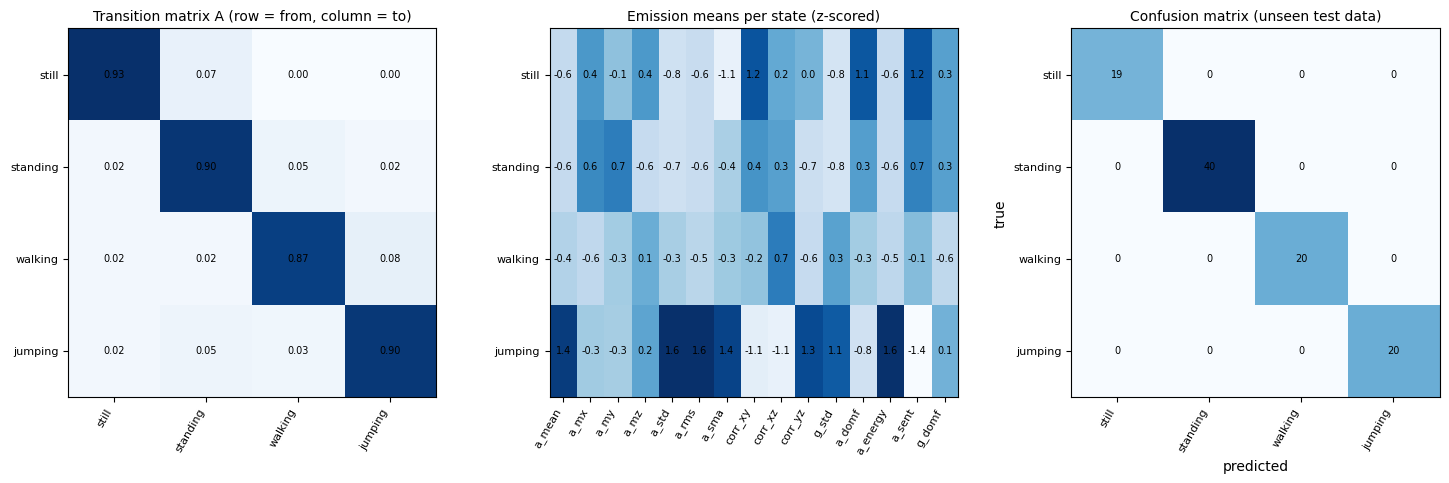

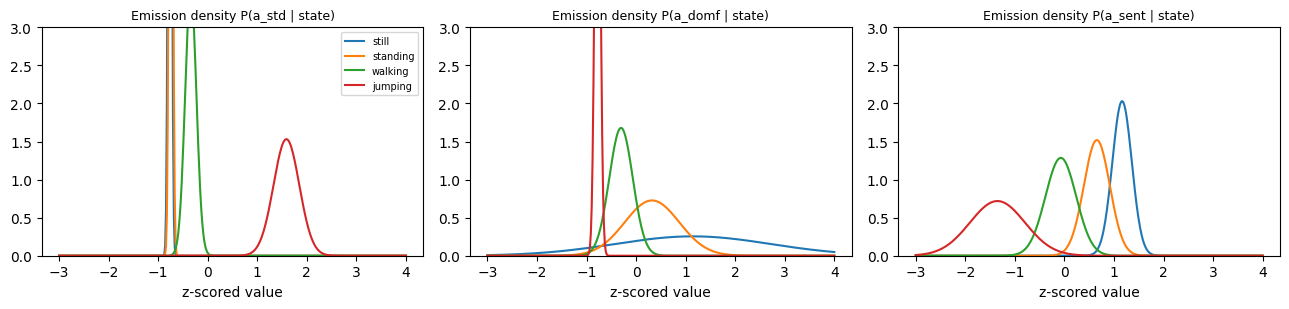

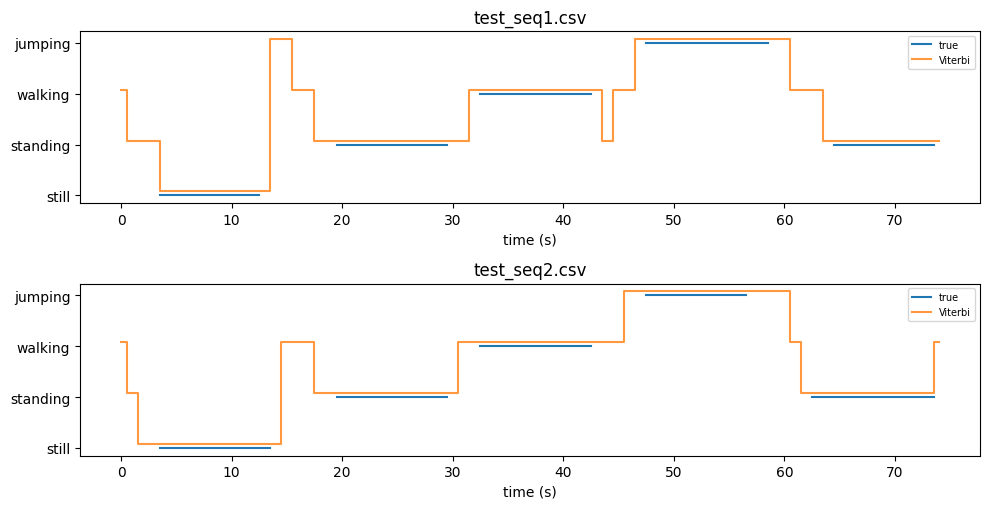

In [10]:
def heat(ax, M, xl, yl, title, fmt='{:.2f}'):
    ax.imshow(M, cmap='Blues'); ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl, fontsize=8); ax.set_title(title, fontsize=10)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]): ax.text(j, i, fmt.format(M[i, j]), ha='center', va='center', fontsize=7)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
heat(ax[0], hmm.A, ACTS, ACTS, 'Transition matrix A (row = from, column = to)')
heat(ax[1], hmm.mu, FEATS, ACTS, 'Emission means per state (z-scored)', '{:.1f}'); ax[1].set_aspect('auto')
heat(ax[2], C1, ACTS, ACTS, 'Confusion matrix (unseen test data)', '{:d}'); ax[2].set_xlabel('predicted'); ax[2].set_ylabel('true')
plt.tight_layout(); plt.savefig(FIG/'heatmaps.png', dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2)); xs = np.linspace(-3, 4, 400)
for a_, fn in zip(ax, ['a_std', 'a_domf', 'a_sent']):
    j = FEATS.index(fn)
    for k, act in enumerate(ACTS):
        s = np.sqrt(hmm.var[k, j]); a_.plot(xs, np.exp(-0.5*((xs-hmm.mu[k, j])/s)**2)/(s*np.sqrt(2*np.pi)), label=act)
    a_.set_title(f'Emission density P({fn} | state)', fontsize=9); a_.set_xlabel('z-scored value'); a_.set_ylim(0, 3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG/'emission_pdfs.png', dpi=150); plt.show()

fig, ax = plt.subplots(len(test_seq), 1, figsize=(10, 2.6*len(test_seq)), squeeze=False)
for i, (name, X, y, _) in enumerate(test_seq):
    t = np.arange(len(y))*STEP/FS; yt = np.where(y >= 0, y, np.nan)
    ax[i, 0].step(t, yt, where='mid', label='true'); ax[i, 0].step(t, hmm.viterbi(X)+0.08, where='mid', label='Viterbi', alpha=.8)
    ax[i, 0].set_yticks(range(4)); ax[i, 0].set_yticklabels(ACTS); ax[i, 0].set_title(name); ax[i, 0].set_xlabel('time (s)'); ax[i, 0].legend(loc='upper right', fontsize=7)
plt.tight_layout(); plt.savefig(FIG/'decoded.png', dpi=150); plt.show()

In [11]:
print('--- Rubric self-check ---')
print('Training files             :', len(audit), '(need >= 50)')
print('Shortest activity (s)      :', round(audit.groupby('activity').sec_after_trim.sum().min(), 1), '(need >= 90)')
print('Features                   :', len(FEATS), '| time-domain:', len([f for f in FEATS if f not in FREQ]), '| FFT-derived:', len(FREQ))
print('Baum-Welch iterations      :', hmm.n_iter, '(stop: relative change in log-likelihood < 1e-6)')
print('Test files                 :', len(test_seq), '(need 2)')
print('Test windows used          :', int(C1.sum()), '| unlabelled windows excluded:', sum(int((y < 0).sum()) for _, _, y, _ in test_seq))
print('Accuracy before / after BW :', round(np.trace(C0)/C0.sum(), 3), '/', round(np.trace(C1)/C1.sum(), 3))

--- Rubric self-check ---
Training files             : 88 (need >= 50)
Shortest activity (s)      : 143.8 (need >= 90)
Features                   : 15 | time-domain: 11 | FFT-derived: 4
Baum-Welch iterations      : 14 (stop: relative change in log-likelihood < 1e-6)
Test files                 : 2 (need 2)
Test windows used          : 99 | unlabelled windows excluded: 51
Accuracy before / after BW : 1.0 / 1.0


### Sampling-rate comparison
Training data contains two recording settings on the same phone: native 50 Hz and 100 Hz (low-pass filtered, then resampled to 50 Hz). The table compares mean feature values per activity and origin; test data is native 50 Hz.

In [12]:
orig = audit.measured_hz.round(-1).map({50.0: '50 Hz native', 100.0: '100 Hz -> 50 Hz'}).fillna('other')
rows = []
for (act, W), origin in zip(train_win, orig):
    for f in ['a_std', 'a_energy', 'a_sent', 'g_std']:
        rows.append(dict(activity=act, origin=origin, feature=f, value=W[:, FEATS.index(f)].mean()))
cmp = pd.DataFrame(rows).groupby(['activity', 'feature', 'origin']).value.mean().unstack('origin').round(4)
display(cmp)

origin             100 Hz -> 50 Hz  50 Hz native
activity feature                                
jumping  a_energy        4080.6488     4813.7936
         a_sent             1.3323        1.7448
         a_std              9.0187        9.7447
         g_std              0.5453        0.4855
standing a_energy           0.8307        0.5159
         a_sent             2.9711        3.0470
         a_std              0.1220        0.1002
         g_std              0.0043        0.0033
still    a_energy           0.0196        0.0385
         a_sent             3.2850        3.4857
         a_std              0.0197        0.0275
         g_std              0.0017        0.0014
walking  a_energy         146.2783      162.6642
         a_sent             2.4960        2.5086
         a_std              1.6507        1.7510
         g_std              0.2754        0.2998

## 5. Analysis and reflection (write in first person, using my own results)
- Easiest and hardest activities to distinguish (read the confusion matrix, do not assume)
- Does A look realistic? It reflects how I chained the training files, so high self-transition probabilities are expected
- Effect of sensor noise, sampling jitter and interpolation (cite the sampling-rate table)
- Generalisation to the unseen data, and the limits of a single-subject test
- Did Baum-Welch help compared with the supervised initialisation?
- Improvements: more subjects and sessions, more sensors, richer features, full covariance, duration modelling